44100,2,204.0
44100,2,153.2604081632653
44100,2,120.05877551020409


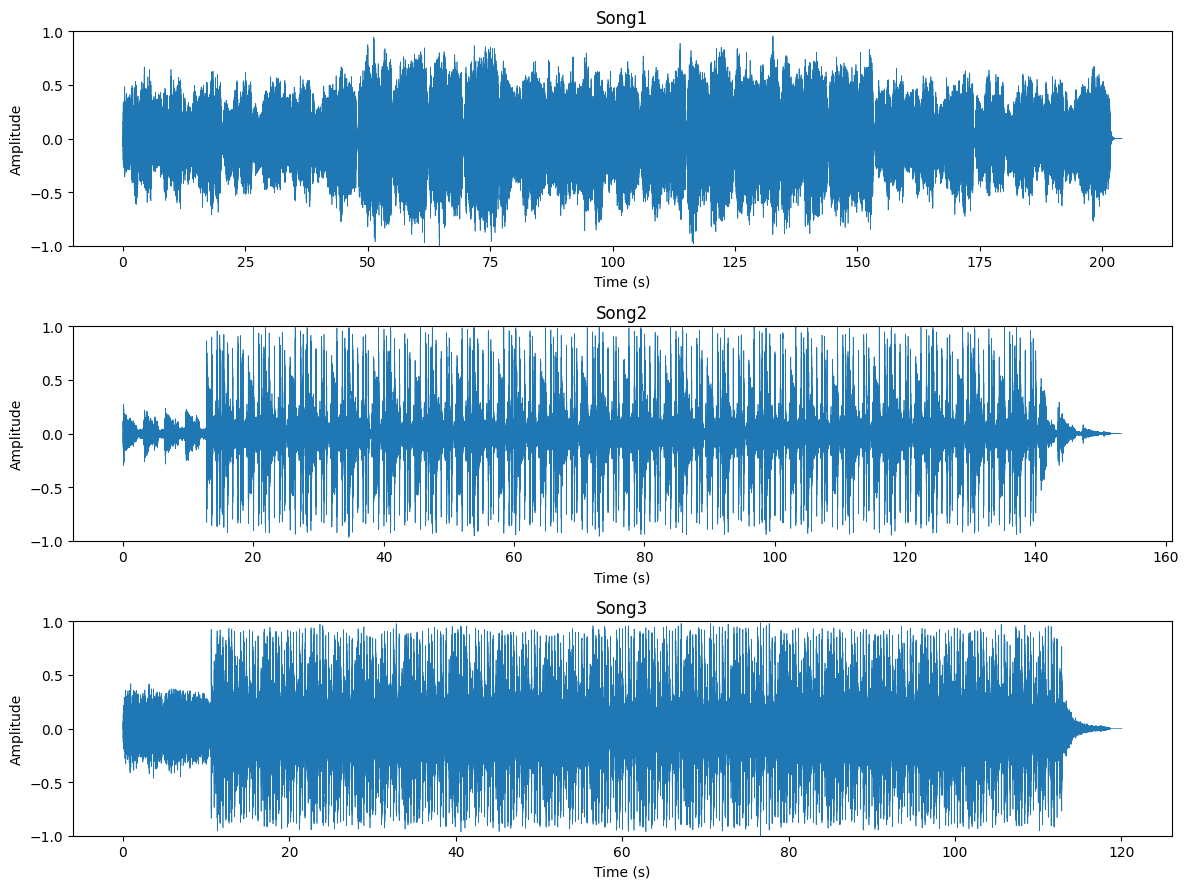

sample_count=512: window = 23 ms, frequency resolution = 43.1 Hz, time between columns = 5.8 ms
sample_count=2048: window = 93 ms, frequency resolution = 10.8 Hz, time between columns = 23.2 ms
sample_count=4096: window = 186 ms, frequency resolution = 5.4 Hz, time between columns = 46.4 ms


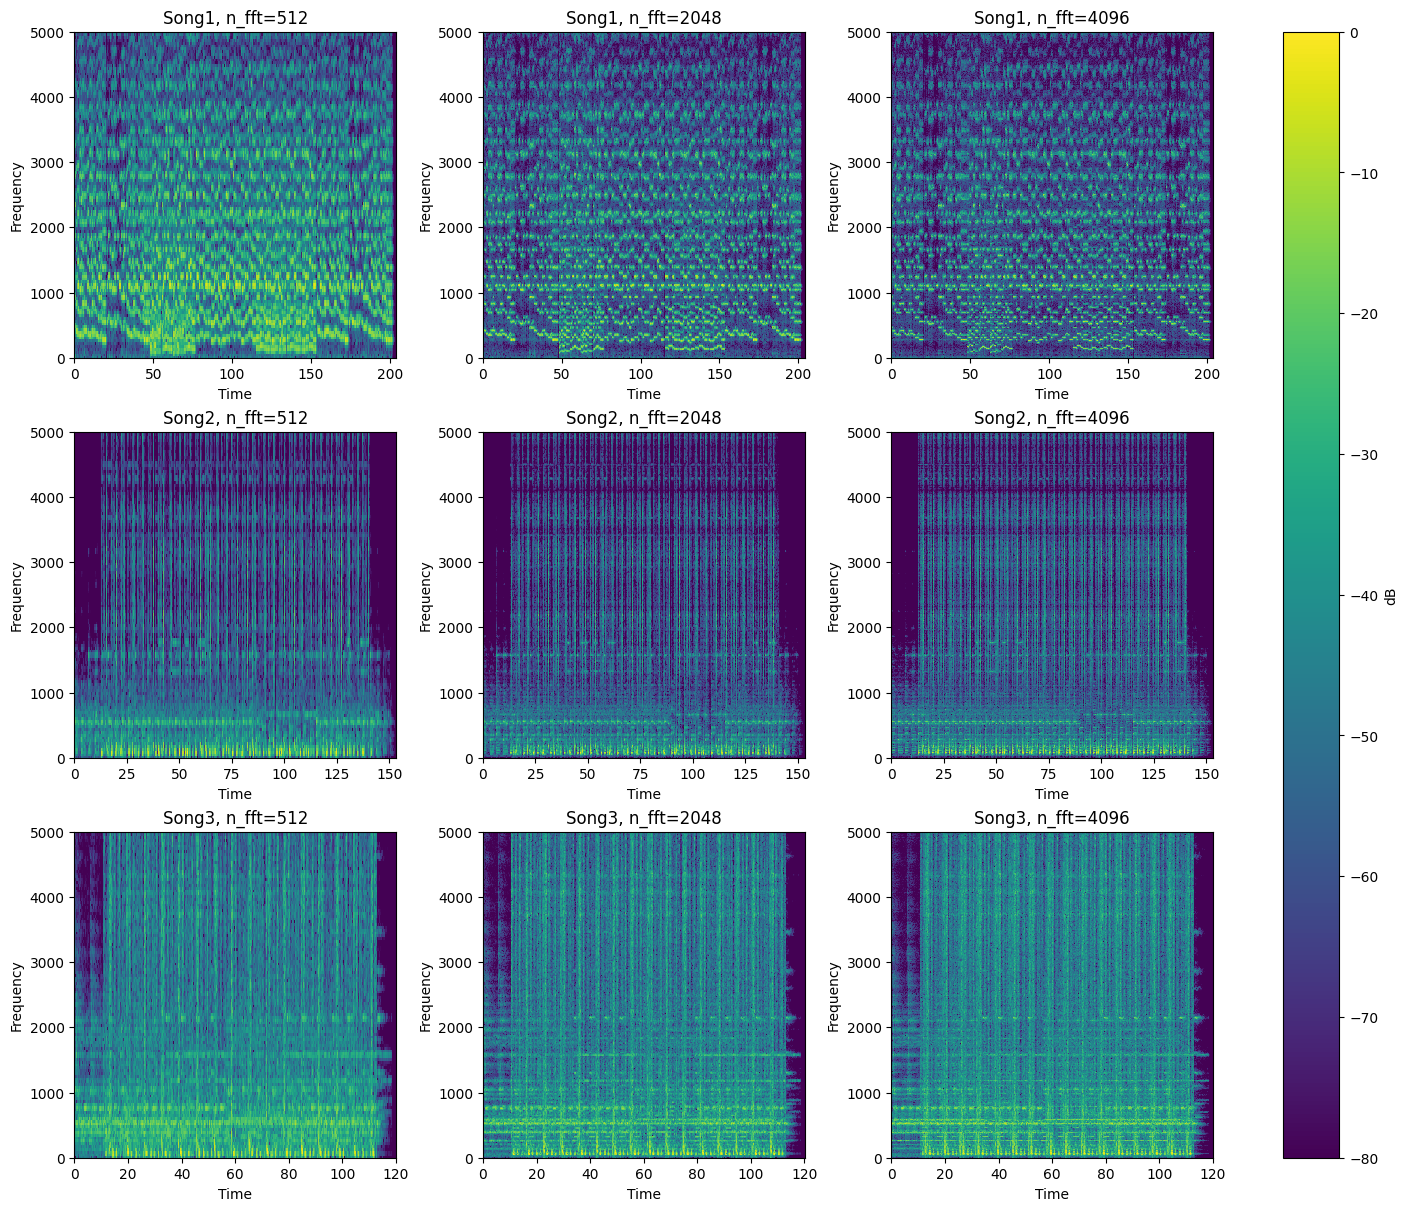

In [1]:
#Group 1 Task 1
import numpy as np
import librosa
import matplotlib.pyplot as plt

t_srate = 22050

paths = {
    "Song1": "/content/Achachak - First Movement.mp3",
    "Song2": "/content/Joint C Beat Laboratory - Margo.mp3",
    "Song3": "/content/Joint C Beat Laboratory - Nerves.mp3"
}

def inspect(path):
  y ,srate = librosa.load(path,sr=None,mono=False)
  #mono = False retains the og file's multi channel data and sr=None also preserves the og audio's srate

  dur = librosa.get_duration(y=y,sr = srate)
  # dur = y.shape[-1]/srate also works as shape[-1] gives the number of samples which when divided by srate gives the duration

  channels = y.shape[0] if y.ndim > 1 else 1
  #y has two dimensions if the file is stereo (channlels, samples) & one if the audio is mono the ifelse condition is for if the file is mono then shape[0]
  #gives the sample which is in the millions which will give deceptive results


  return srate,channels,dur

def load(path,target_srate = t_srate , normalize = True):
  y,srate = librosa.load(path,sr=None,mono=False)

  if y.ndim > 1 :
    # mostly efficiency nothing else as each step which uses y_mono now only handles a 1D structure and needs to compute less.(can skip)
    y_mono = librosa.to_mono(y)
  else:
    y_mono = y

  if srate!=target_srate:
    #resample takes in the audio file and changes the sampling rate, we set the target at 22050 Hz for uniformity across code
    y_resampled = librosa.resample(y_mono,orig_sr=srate,target_sr=target_srate)
  else:
    y_resampled = y_mono
  if normalize:
    peak = np.max(np.abs(y_resampled))
    if peak>0:
      y_resampled = y_resampled/peak
      #just to normalise the audio so that the loudest sample is exacly at height 1, improves consistency and also doesn't change the overall audio as each sample is multiplied by the same factor

  return y_resampled,target_srate
songs = {}
for name,path in paths.items():
  srate,channels,dur  = inspect(path)
  print(f"{srate},{channels},{dur}")
  y,sr = load(path)
  songs[name] = (y,sr)

#this creates a blankspace where we can plot the graph
fig, axes = plt.subplots(len(songs), 1, figsize=(12, 3 * len(songs)))

#ax(ax is the commonly used term, like how we use name use head pointer for linked lists) represents a plot area,(for 3 plots) it is the top most area for the first iteration, middle for the second and bottom for the third
#for each iteration the plot area has its own axes named t and y,here (t is basically the time axis, y is the audio data)
for ax, (name, (y, sr)) in zip(axes, songs.items()):
    # time axis: sample index divided by samples per second gives seconds
    t = np.arange((y.shape[0])) / sr
    ax.plot(t, y, linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    #we do a y limit to fix a vertical scale so that song peaks can directly be compared
    ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

#Group 1 Task 2


#sample_count is basically the no. of samples in a window(basically a slice of the audio data) and hop_length basically describes the distance between the starting of windows
#we keep the windows overlapping to prevent losses, as end to end joining may cause some discrepancies
def comp_spectrogram(y, sample_count= 2048,hop_length= 512):

  #this is basically a way to perform stft(short-time fourier transform) in python to convert a signal from time domain to complex time-frequency domain, y_stft will basically be a complex-valued matrix
  y_stft = librosa.stft(y,n_fft=sample_count,hop_length=hop_length)

  #just keeping each frequency's strength and throwing away the phase
  y_mag = np.abs(y_stft)

  # we use the max as the ref, hence the max value is set to be 0, this makes the quiet details visible
  y_db = librosa.amplitude_to_db(y_mag, ref = np.max)

  return y_db

def plot_spectrogram(y,srate, sample_count,hop_length,ax,max_freq = 5000):

  #converts the frames to tims
  time = librosa.frames_to_time(np.arange(y.shape[1]),sr = srate,hop_length=hop_length)

  #returns the frequency of each row
  freq = librosa.fft_frequencies(sr=srate,n_fft=sample_count)

  #draws each cell as a rectangle positioned by time and freq , the shading = "auto" selects the optimal shadin mode to be used, it's like how we used loc='best' when making a legend in matplotlib
  spectrogram = ax.pcolormesh(time,freq,y,shading = "auto")


  ax.set_ylim(0,max_freq)
  ax.set_xlabel("Time")
  ax.set_ylabel("Frequency")

  return spectrogram


#this below shows the number associated with different samples per window
for sample_count in [512, 2048, 4096]:
    hop = sample_count // 4
    print(f"sample_count={sample_count}: window = {1000 * sample_count / t_srate:.0f} ms, "
          f"frequency resolution = {t_srate / sample_count:.1f} Hz, "
          f"time between columns = {1000 * hop / t_srate:.1f} ms")

window_sizes = [512, 2048,4096]
#added the constrained_layout as the color_bar was clipping inside the graphs
fig, axes = plt.subplots(len(songs), len(window_sizes), figsize=(14, 4 * len(songs)),constrained_layout=True)



for i, (name, (y, sr)) in enumerate(songs.items()):
    for j, n in enumerate(window_sizes):
        hop = n // 4   # same 75% overlap, so only the window size changes
        y_db = comp_spectrogram(y, n, hop)
        img = plot_spectrogram(y_db, sr, n, hop, axes[i, j])
        axes[i, j].set_title(f"{name}, n_fft={n}")

fig.colorbar(img, ax=axes, label="dB")
plt.show()

#i personally think 2048 looks the best with low smearing and stretchiness, the smearing is slightly more apparent with 512 and 4096 looks very sparse
#I think 2048 is a nice middle ground
SAMPLE_COUNT, HOP_LENGTH = 2048,512

specs = {name: comp_spectrogram(y, SAMPLE_COUNT, HOP_LENGTH) for name, (y, sr) in songs.items()}
